In [ ]:
import os, sys, re, json, math, warnings, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x
warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = print

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# ---- paths (same layout as week 1) ----
BASE     = Path(os.environ.get("MCD_BASE", "/content/drive/MyDrive/MCD_rPPG"))
DB_PATH  = BASE / "metadata" / "db.csv"          # full 600-patient label file
RAW      = BASE / "raw"                          # raw/video, raw/ppg_sync, raw/meta, ...
RGB_DIR  = BASE / "rgb_signals"                  # week-1 whole-face traces: <video>.avi.npy, shape (N,3)
ROI_DIR  = BASE / "roi_traces"                   # §7 output: <video>.avi.npz (multi-ROI)
OUT_DIR  = BASE / "results" / "week2_baselines"
OUT_DIR.mkdir(parents=True, exist_ok=True)
ROI_DIR.mkdir(parents=True, exist_ok=True)

HF_REPO  = "wengziheng/mcd_rppg"
TARGETS  = ["temperature", "stress"]
SEED     = 43            # same seed + 20% test fraction as MCD-rPPG-baselines/split_data.py
TEST_FRACTION = 0.20
# Fallback only. §4.1 measures the real fps from the meta files and prints it per camera.
CAMERA_DEFAULT_FPS = {"FullHDwebcam": 30.0, "USBVideo": 30.0, "IriunWebcam": 24.0}
np.random.seed(SEED)
print("BASE:", BASE, "| db.csv exists:", DB_PATH.exists())

Mounted at /content/drive
BASE: /content/drive/MyDrive/MCD_rPPG | db.csv exists: True


(3600, 28) patients: 600

=== temperature ===
patients whose value differs before vs after : 17.3%
sessions whose value differs across cameras  : 0.0%
distinct values: 12 | smallest step between values: 0.100
{'count': 1200.0, 'mean': 36.564, 'std': 0.133, 'min': 36.0, '25%': 36.5, '50%': 36.6, '75%': 36.6, 'max': 37.5}
most common values (share of sessions): {36.6: 0.402, 36.5: 0.227, 36.7: 0.158, 36.4: 0.094, 36.3: 0.061}
after − before: mean +0.012, sd 0.067, paired t p=2.24e-05

=== stress ===
patients whose value differs before vs after : 0.7%
sessions whose value differs across cameras  : 0.0%
distinct values: 107 | smallest step between values: 0.010
{'count': 1200.0, 'mean': 3.039, 'std': 1.458, 'min': 1.0, '25%': 2.0, '50%': 3.0, '75%': 4.0, 'max': 7.52}
most common values (share of sessions): {3.0: 0.19, 4.0: 0.176, 2.0: 0.174, 1.0: 0.167, 5.0: 0.048}
after − before: mean +0.002, sd 0.125, paired t p=0.676


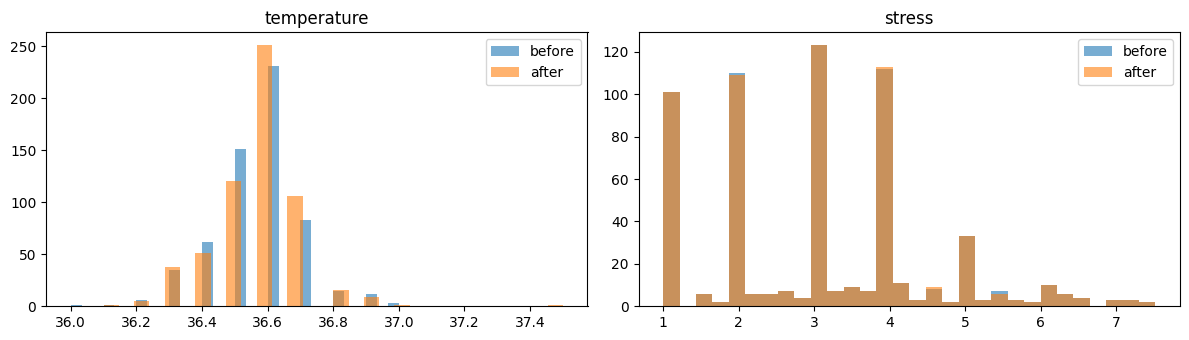

In [ ]:
db = pd.read_csv(DB_PATH)
db["patient_id"] = db["patient_id"].astype(str)
db["video_name"] = db["video"].map(lambda p: Path(p).name)
db["step_after"] = (db["step"] == "after").astype(int)
db["sex_m"] = (db["sex"] == "M").astype(int)
print(db.shape, "patients:", db.patient_id.nunique())

sess = db.drop_duplicates(["patient_id", "step"]).copy()   # one row per (patient, before/after)
for t in TARGETS:
    across_steps = (db.groupby("patient_id")[t].nunique() > 1).mean()
    across_cams  = (db.groupby(["patient_id", "step"])[t].nunique() > 1).mean()
    vals = np.sort(sess[t].unique())
    print(f"\n=== {t} ===")
    print(f"patients whose value differs before vs after : {across_steps:.1%}")
    print(f"sessions whose value differs across cameras  : {across_cams:.1%}")
    print(f"distinct values: {len(vals)} | smallest step between values: {np.min(np.diff(vals)) if len(vals)>1 else np.nan:.3f}")
    print(sess[t].describe().round(3).to_dict())
    top = sess[t].value_counts(normalize=True).head(5).round(3)
    print("most common values (share of sessions):", top.to_dict())
    piv = sess.pivot_table(index="patient_id", columns="step", values=t)
    if {"before", "after"} <= set(piv.columns):
        d = (piv["after"] - piv["before"]).dropna()
        print(f"after − before: mean {d.mean():+.3f}, sd {d.std():.3f}, paired t p={stats.ttest_rel(piv['after'], piv['before'], nan_policy='omit').pvalue:.3g}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, t in zip(ax, TARGETS):
    for st, c in [("before", "tab:blue"), ("after", "tab:orange")]:
        a.hist(sess.loc[sess.step == st, t], bins=30, alpha=.6, label=st, color=c)
    a.set_title(t); a.legend()
plt.tight_layout(); plt.show()

In [ ]:
patients = db["patient_id"].unique()
train_p, test_p = train_test_split(patients, test_size=TEST_FRACTION, random_state=SEED)
test_set = set(test_p)
db["split"] = np.where(db.patient_id.isin(test_set), "test", "train")
sess["split"] = np.where(sess.patient_id.isin(test_set), "test", "train")
assert not (set(train_p) & test_set)
pd.DataFrame({"patient_id": patients, "split": np.where(np.isin(patients, test_p), "test", "train")}) \
  .to_csv(OUT_DIR / "patient_split.csv", index=False)
print(f"train patients {len(train_p)} | test patients {len(test_p)} | saved {OUT_DIR/'patient_split.csv'}")

train patients 480 | test patients 120 | saved /content/drive/MyDrive/MCD_rPPG/results/week2_baselines/patient_split.csv


In [ ]:
def reg_metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    ok = np.isfinite(y) & np.isfinite(p); y, p = y[ok], p[ok]
    out = dict(MAE=np.mean(np.abs(y - p)), RMSE=np.sqrt(np.mean((y - p) ** 2)))
    out["R2"] = 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2) if np.var(y) > 0 else np.nan
    out["Pearson_r"] = stats.pearsonr(y, p)[0] if (np.std(p) > 1e-12 and np.std(y) > 0) else np.nan
    return out

MODELS = {
    "Const-mean":   lambda: DummyRegressor(strategy="mean"),
    "Const-median": lambda: DummyRegressor(strategy="median"),
    "Ridge":        lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                          RidgeCV(alphas=np.logspace(-2, 4, 25))),
    "RandomForest": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                          RandomForestRegressor(n_estimators=400, min_samples_leaf=5,
                                                                max_features=0.5, n_jobs=-1, random_state=SEED)),
    "HistGBR-MAE":  lambda: HistGradientBoostingRegressor(loss="absolute_error", max_depth=3, learning_rate=0.05,
                                                          max_iter=300, min_samples_leaf=20,
                                                          l2_regularization=1.0, random_state=SEED),
}

def run_experiment(df, feats, target, model_name, n_splits=5):
    """df: one row per sample with columns patient_id, step, split, target, feats.
    Returns predictions for CV (out-of-fold on train patients) and test (model refit on all train)."""
    df = df[np.isfinite(df[target])].reset_index(drop=True)
    tr, te = df[df.split == "train"].reset_index(drop=True), df[df.split == "test"].reset_index(drop=True)
    X = lambda d: d[feats].to_numpy(float) if feats else np.zeros((len(d), 1))
    preds = []
    k = min(n_splits, tr.patient_id.nunique())
    if k >= 2:
        oof = np.full(len(tr), np.nan)
        for a, b in GroupKFold(n_splits=k).split(X(tr), tr[target], tr.patient_id):
            m = MODELS[model_name](); m.fit(X(tr)[a], tr[target].values[a]); oof[b] = m.predict(X(tr)[b])
        preds.append(tr.assign(pred=oof, protocol="cv"))
    if len(te) and len(tr):
        m = MODELS[model_name](); m.fit(X(tr), tr[target].values)
        preds.append(te.assign(pred=m.predict(X(te)), protocol="test"))
    keep = ["patient_id", "step", "protocol", target, "pred"] + (["camera"] if "camera" in df else [])
    return pd.concat(preds)[keep] if preds else pd.DataFrame(columns=keep)

def summarise(pred, target, feature_set, model_name, level):
    rows = []
    for prot, g in pred.groupby("protocol"):
        if level == "session" and "camera" in g:          # average the 3 cameras of a session
            g = g.groupby(["patient_id", "step"], as_index=False)[[target, "pred"]].mean()
        rows.append(dict(target=target, feature_set=feature_set, model=model_name, level=level, protocol=prot,
                         n_patients=g.patient_id.nunique(), n_samples=len(g), **reg_metrics(g[target], g["pred"])))
    return rows

def run_grid(df, feature_sets, targets=TARGETS, models=MODELS, level="session"):
    rows, all_preds = [], {}
    for t in targets:
        for fs_name, feats in feature_sets.items():
            feats = [f for f in feats if f in df.columns]
            for m in models:
                if m.startswith("Const") and fs_name != list(feature_sets)[0]:
                    continue                                   # constants don't depend on features
                p = run_experiment(df, feats, t, m)
                name = "none (B0)" if m.startswith("Const") else fs_name
                rows += summarise(p, t, name, m, level)
                if level == "recording":
                    rows += summarise(p, t, name, m, "session")
                all_preds[(t, name, m)] = p
    res = pd.DataFrame(rows)
    # skill = how much of the constant-median error is removed (same rows, same protocol, same level)
    base = res[res.model == "Const-median"].set_index(["target", "level", "protocol"])["MAE"]
    res["skill_vs_B0"] = [1 - r.MAE / base.get((r.target, r.level, r.protocol), np.nan) for r in res.itertuples()]
    return res, all_preds

def show(res, protocol="test", level="session"):
    r = res[(res.protocol == protocol) & (res.level == level)].copy()
    for t, g in r.groupby("target"):
        print(f"\n--- {t} | {protocol} | {level}-level ---")
        display(g.sort_values("MAE")[["feature_set", "model", "n_patients", "n_samples", "MAE", "RMSE",
                                      "R2", "Pearson_r", "skill_vs_B0"]].round(4).reset_index(drop=True))

In [ ]:
def _try_float(s):
    try:
        return float(s)
    except ValueError:
        return None

def read_meta_fps(path, n_frames=None):
    """Estimate fps from a meta file. Handles a numeric timestamp column (s / ms / µs / ns)
    or a datetime string per line. Returns (fps, how) or (None, reason)."""
    path = Path(path)
    if not path.exists():
        return None, "no meta file"
    lines = [l.strip() for l in open(path, errors="ignore") if l.strip()]
    if len(lines) < 20:
        return None, "meta too short"
    # 1) numeric columns
    rows = [[v for v in (_try_float(t) for t in re.split(r"[\s,;]+", l)) if v is not None] for l in lines]
    k = min(len(r) for r in rows)
    if k > 0:
        arr = np.array([r[:k] for r in rows], float)
        for c in range(k):
            d = np.diff(arr[:, c])
            if np.median(d) <= 0 or np.mean(d > 0) < 0.95:
                continue
            span = arr[-1, c] - arr[0, c]
            for scale, unit in [(1, "s"), (1e3, "ms"), (1e6, "us"), (1e9, "ns")]:
                fps = (len(arr) - 1) / (span / scale)
                if 10 <= fps <= 65:
                    return fps, f"numeric col {c} ({unit})"
    # 2) datetime strings (try whole line, then first two tokens)
    for cand in (lines, [" ".join(l.split()[:2]) for l in lines], [l.split()[-1] for l in lines]):
        ts = pd.to_datetime(pd.Series(cand), errors="coerce", format="mixed")
        if ts.notna().mean() > 0.9:
            ts = ts.dropna()
            span = (ts.iloc[-1] - ts.iloc[0]).total_seconds()
            if span > 0:
                fps = (len(ts) - 1) / span
                if 10 <= fps <= 65:
                    return fps, "datetime"
    return None, "unrecognised format"

def show_meta_example():
    files = sorted((RAW / "meta").glob("*.txt"))
    if files:
        print("Example meta file:", files[0].name)
        print("".join(open(files[0], errors="ignore").readlines()[:4]))

show_meta_example()
fps_rows = []
for r in tqdm(db.itertuples(), total=len(db), desc="fps"):
    meta_path = RAW / r.meta
    if not meta_path.exists():
        continue
    fps, how = read_meta_fps(meta_path)
    fps_rows.append(dict(video_name=r.video_name, camera=r.camera, fps_meta=fps, fps_how=how))
fps_df = pd.DataFrame(fps_rows, columns=["video_name", "camera", "fps_meta", "fps_how"])
if len(fps_df):
    print(fps_df.groupby("camera")["fps_meta"].describe().round(2))
    print(fps_df.fps_how.value_counts())
FPS_MAP = dict(zip(fps_df.video_name, fps_df.fps_meta)) if len(fps_df) else {}

def get_fps(video_name, camera):
    f = FPS_MAP.get(video_name)
    return float(f) if f is not None and np.isfinite(f) else CAMERA_DEFAULT_FPS[camera]

Example meta file: 1113_FullHDwebcam_after.txt

1  2023-10-19 14:58:54.277473
2  2023-10-19 14:58:54.309356
3  2023-10-19 14:58:54.341272



fps:   0%|          | 0/3600 [00:00<?, ?it/s]

              count   mean   std    min    25%    50%    75%    max
camera                                                             
FullHDwebcam  200.0  29.95  0.09  29.40  29.97  29.99  29.99  29.99
IriunWebcam   200.0  23.93  0.37  20.85  23.99  24.00  24.00  24.00
USBVideo      200.0  29.96  0.09  29.43  29.97  30.00  30.00  30.00
fps_how
datetime    600
Name: count, dtype: int64


In [ ]:
def interp_nans(x):
    x = np.asarray(x, float).copy()
    if x.ndim == 1:
        bad = ~np.isfinite(x)
        if bad.all():
            return x
        if bad.any():
            x[bad] = np.interp(np.flatnonzero(bad), np.flatnonzero(~bad), x[~bad])
        return x
    return np.column_stack([interp_nans(x[:, j]) for j in range(x.shape[1])])

def repair_duplicate_frames(rgb):
    """Frames identical to the previous one (camera re-sent the last frame) create a periodic
    step artefact, e.g. 1 dup every 12 frames at 30 fps = a fake 2.5 Hz (150 BPM) peak.
    Replace them by interpolation. Returns (repaired_rgb, duplicate_fraction)."""
    rgb = np.asarray(rgb, float)
    dup = np.r_[False, np.all(np.diff(rgb, axis=0) == 0, axis=1)]
    out = rgb.copy(); out[dup] = np.nan
    return interp_nans(out), dup.mean()

def pos_wang(rgb, fs, win_sec=1.6):
    """Plane-Orthogonal-to-Skin (Wang et al. 2017), overlap-add."""
    rgb = np.asarray(rgb, float); N = len(rgb); l = int(np.ceil(win_sec * fs))
    P = np.array([[0, 1, -1], [-2, 1, 1]], float); H = np.zeros(N)
    for n in range(l, N + 1):
        C = rgb[n - l:n]; C = C / (C.mean(0) + 1e-9)
        S = C @ P.T
        h = S[:, 0] + (S[:, 0].std() / (S[:, 1].std() + 1e-9)) * S[:, 1]
        H[n - l:n] += h - h.mean()
    return H

def bandpass(x, fs, lo=0.7, hi=3.5, order=3):
    b, a = signal.butter(order, [lo / (fs / 2), min(hi / (fs / 2), 0.99)], btype="band")
    return signal.filtfilt(b, a, x)

def _band_power(f, p, lo, hi):
    m = (f >= lo) & (f < hi)
    return np.trapezoid(p[m], f[m]) if m.sum() > 1 else np.nan

HR_LO, HR_HI = 0.7, 3.0          # 42–180 BPM (db.csv pulse range is 49–153)

def hr_peak_freq(f, p, lo=HR_LO, hi=HR_HI, n_harm=3):
    """Harmonic-sum pitch estimate. Scores each candidate f0 by P(f0)+P(2f0)+P(3f0)
    (each harmonic down-weighted), so a strong 2nd harmonic (dicrotic notch, week-1's
    'harmonic peak' errors) votes FOR the true f0 instead of beating it."""
    m = (f >= lo) & (f <= hi)
    cand = f[m]
    score = p[m].copy()
    for k in range(2, n_harm + 1):
        score += np.interp(k * cand, f, p, right=0.0) / k
    return cand[np.argmax(score)]

def bvp_features(x, fs, prefix):
    """x: raw pulse signal (POS output or contact PPG) at fs Hz. Returns dict of features."""
    F = {}
    x = interp_nans(np.asarray(x, float))
    if len(x) < fs * 20 or not np.isfinite(x).all() or np.std(x) == 0:
        return F
    raw = signal.detrend(x)
    bvp = bandpass(raw, fs); bvp = (bvp - bvp.mean()) / (bvp.std() + 1e-12)
    # --- spectral HR / quality ---
    f, p = signal.welch(bvp, fs=fs, nperseg=int(min(len(bvp), 12 * fs)), nfft=8192)
    m = (f >= HR_LO) & (f <= HR_HI)
    f0 = hr_peak_freq(f, p)
    sig = _band_power(f, p, f0 - .1, f0 + .1) + _band_power(f, p, 2 * f0 - .1, 2 * f0 + .1)
    tot = _band_power(f, p, 0.5, 4.0)
    F["hr_fft"] = 60 * f0
    F["snr_db"] = 10 * np.log10(sig / max(tot - sig, 1e-12))
    pn = p[m] / p[m].sum(); F["spec_entropy"] = -np.sum(pn * np.log(pn + 1e-12)) / np.log(len(pn))
    # --- windowed HR (trend, stability; post-exercise recovery) ---
    w, s = int(20 * fs), int(5 * fs); hrs = []
    for a in range(0, len(bvp) - w + 1, s):
        fw, pw = signal.periodogram(bvp[a:a + w], fs=fs, nfft=4096)
        hrs.append(60 * hr_peak_freq(fw, pw))
    hrs = np.array(hrs)
    if len(hrs) >= 3:
        t = np.arange(len(hrs)) * 5 / 60
        F["hr_win_median"] = np.median(hrs); F["hr_win_iqr"] = stats.iqr(hrs)
        F["hr_slope_bpm_per_min"] = np.polyfit(t, hrs, 1)[0]
    # --- beat-to-beat (upsample to 4x for timing precision) ---
    up = 4; xu = signal.resample_poly(bvp, up, 1); fu = fs * up
    pk, _ = signal.find_peaks(xu, distance=int(fu / 3.5), prominence=0.3)
    ibi = np.diff(pk) / fu * 1000.0
    ok = (ibi > 285) & (ibi < 1500)
    if ok.sum() > 10:
        med = np.median(ibi[ok]); ok &= np.abs(ibi - med) < 0.3 * med
    F["ibi_valid_frac"] = ok.mean() if len(ibi) else 0.0
    if ok.sum() > 20:
        ib = ibi[ok]; d = np.diff(ibi)[ok[1:] & ok[:-1]]
        F["hr_peaks"] = 60000 / np.mean(ib); F["sdnn"] = np.std(ib)
        F["rmssd"] = np.sqrt(np.mean(d ** 2)) if len(d) else np.nan
        F["pnn50"] = np.mean(np.abs(d) > 50) if len(d) else np.nan
        F["ibi_cv"] = np.std(ib) / np.mean(ib)
        F["log_rmssd"] = np.log(F["rmssd"] + 1e-6)
        # frequency-domain HRV on the 4 Hz-resampled tachogram
        tb = np.cumsum(ibi)[ok] / 1000.0
        if tb[-1] - tb[0] > 60:
            tt = np.arange(tb[0], tb[-1], 0.25); tach = np.interp(tt, tb, ib); tach -= tach.mean()
            fh, ph = signal.welch(tach, fs=4, nperseg=min(len(tach), 256))
            lf, hf = _band_power(fh, ph, .04, .15), _band_power(fh, ph, .15, .4)
            F["lf"], F["hf"] = lf, hf; F["lf_hf"] = lf / hf if hf > 0 else np.nan
            F["lf_nu"] = lf / (lf + hf) if (lf + hf) > 0 else np.nan
            mr = (fh >= .1) & (fh <= .5)
            F["resp_rsa_bpm"] = 60 * fh[mr][np.argmax(ph[mr])] if mr.sum() else np.nan
        # mean beat morphology (trough-to-trough, resampled to 50 pts)
        tr_, _ = signal.find_peaks(-xu, distance=int(fu / 3.5), prominence=0.3)
        beats = [signal.resample(xu[a:b], 50) for a, b in zip(tr_[:-1], tr_[1:]) if 0.285 * fu < b - a < 1.5 * fu]
        if len(beats) > 10:
            bt = np.median(np.array(beats), 0); bt = (bt - bt.min()) / (np.ptp(bt) + 1e-12)
            F["beat_rise_frac"] = np.argmax(bt) / 50.0
            F["beat_width50"] = np.mean(bt > 0.5)
            F["beat_skew"] = stats.skew(bt)
    F["sig_skew"], F["sig_kurt"] = stats.skew(bvp), stats.kurtosis(bvp)
    # respiration from the slow component of the raw signal
    if fs > 2:
        lo = signal.filtfilt(*signal.butter(2, [0.1 / (fs / 2), 0.5 / (fs / 2)], btype="band"), raw)
        fr, pr = signal.welch(lo, fs=fs, nperseg=int(min(len(lo), 60 * fs)))
        mr = (fr >= .1) & (fr <= .5); F["resp_lowfreq_bpm"] = 60 * fr[mr][np.argmax(pr[mr])]
    return {f"{prefix}_{k}": v for k, v in F.items()}

def colour_features(rgb, fs, prefix):
    """Skin-colour statistics: possible links to temperature (flushing / perfusion) and to the camera."""
    rgb = interp_nans(np.asarray(rgb, float)); mu = np.nanmean(rgb, 0); s = mu.sum() + 1e-9
    F = {"R": mu[0], "G": mu[1], "B": mu[2], "r_chrom": mu[0] / s, "g_chrom": mu[1] / s,
         "R_over_G": mu[0] / (mu[1] + 1e-9), "lum_drift": np.polyfit(np.arange(len(rgb)) / fs, rgb.mean(1), 1)[0]}
    g = rgb[:, 1]
    if len(g) > fs * 20:
        F["G_pulse_acdc"] = np.std(bandpass(signal.detrend(g), fs)) / (np.mean(g) + 1e-9)
    return {f"{prefix}_{k}": v for k, v in F.items()}

def load_ppg_sync(path):
    vals = [int(float(l.split()[0])) for l in open(path) if l.strip()]
    return np.asarray(vals, float)

In [ ]:
import cv2, urllib.request

def _cascade(name):
    roots = []
    if hasattr(cv2, "data") and getattr(cv2.data, "haarcascades", None):
        roots.append(Path(cv2.data.haarcascades))
    roots += [Path(os.environ.get("CASCADE_DIR", "/content")), Path(".")]
    for r in roots:
        if (r / name).exists():
            return cv2.CascadeClassifier(str(r / name))
    dst = Path(os.environ.get("CASCADE_DIR", "/content")) / name
    try:
        dst.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/{name}", dst)
        return cv2.CascadeClassifier(str(dst))
    except Exception as e:
        print("could not load", name, e); return None

ROI_NAMES = ["face", "forehead", "left_cheek", "right_cheek"]
ROI_BOXES = {  # fractions of the face box: (x0, x1, y0, y1)
    "face": (0.15, 0.85, 0.10, 0.90), "forehead": (0.25, 0.75, 0.05, 0.25),
    "left_cheek": (0.12, 0.38, 0.50, 0.75), "right_cheek": (0.62, 0.88, 0.50, 0.75)}

def _detect(gray, dets, scale=0.5):
    g = cv2.resize(gray, None, fx=scale, fy=scale)
    best = None
    for kind, det in dets.items():
        if det is None or det.empty():
            continue
        for flip in ([False, True] if kind == "profile" else [False]):
            img = cv2.flip(g, 1) if flip else g
            faces = det.detectMultiScale(img, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))
            for (x, y, w, h) in faces:
                if flip:
                    x = img.shape[1] - x - w
                if best is None or w * h > best[2] * best[3]:
                    best = (x / scale, y / scale, w / scale, h / scale)
    return best

def extract_roi_traces(video_path, out_path, detect_every=10, ema=0.3, max_frames=None):
    dets = {"frontal": _cascade("haarcascade_frontalface_default.xml"),
            "profile": _cascade("haarcascade_profileface.xml")}
    cap = cv2.VideoCapture(str(video_path))
    fps_c = cap.get(cv2.CAP_PROP_FPS)
    traces, dup, found, box, prev_small = [], [], [], None, None
    i = 0
    while True:
        ok, bgr = cap.read()
        if not ok or (max_frames and i >= max_frames):
            break
        small = cv2.resize(bgr, (64, 48), interpolation=cv2.INTER_AREA)
        dup.append(prev_small is not None and np.array_equal(small, prev_small)); prev_small = small
        if i % detect_every == 0:
            d = _detect(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), dets)
            if d is not None:
                box = np.array(d) if box is None else (1 - ema) * box + ema * np.array(d)
            found.append(d is not None)
        else:
            found.append(found[-1] if found else False)
        row = np.full((len(ROI_NAMES), 3), np.nan, np.float32)
        if box is not None:
            x, y, w, h = box
            rgb = bgr[..., ::-1]
            for k, n in enumerate(ROI_NAMES):
                fx0, fx1, fy0, fy1 = ROI_BOXES[n]
                xa, xb = int(max(0, x + fx0 * w)), int(min(bgr.shape[1], x + fx1 * w))
                ya, yb = int(max(0, y + fy0 * h)), int(min(bgr.shape[0], y + fy1 * h))
                if xb - xa < 4 or yb - ya < 4:
                    continue
                patch = rgb[ya:yb, xa:xb]
                ycc = cv2.cvtColor(bgr[ya:yb, xa:xb], cv2.COLOR_BGR2YCrCb)
                skin = (ycc[..., 1] >= 133) & (ycc[..., 1] <= 173) & (ycc[..., 2] >= 77) & (ycc[..., 2] <= 127)
                px = patch[skin] if skin.sum() > 0.2 * skin.size else patch.reshape(-1, 3)
                row[k] = px.mean(0)
        traces.append(row); i += 1
    cap.release()
    traces = np.array(traces, np.float32)
    np.savez_compressed(out_path, traces=traces, roi_names=np.array(ROI_NAMES), dup=np.array(dup),
                        face_found=np.array(found), fps_container=fps_c)
    return dict(frames=len(traces), fps_container=fps_c, dup_frac=float(np.mean(dup)) if dup else np.nan,
                face_found_frac=float(np.mean(found)) if found else 0.0)

def process_from_hf(rows, tmp_dir="/content/tmp_video", keep_video=False):
    """rows: DataFrame slice of db. Uses a local copy in RAW/video if present, else streams from HF."""
    from huggingface_hub import hf_hub_download
    log = []
    for r in tqdm(list(rows.itertuples()), desc="extract ROI traces"):
        out = ROI_DIR / f"{r.video_name}.npz"
        if out.exists():
            continue
        t0 = time.time(); local = RAW / r.video; downloaded = False
        try:
            if not local.exists():
                local = Path(hf_hub_download(repo_id=HF_REPO, filename=r.video, repo_type="dataset", local_dir=tmp_dir))
                downloaded = True
            info = extract_roi_traces(local, out)
            log.append(dict(video_name=r.video_name, secs=time.time() - t0, **info))
        except Exception as e:
            log.append(dict(video_name=r.video_name, error=repr(e)))
        finally:
            if downloaded and not keep_video and Path(local).exists():
                os.remove(local)
        pd.DataFrame(log).to_csv(OUT_DIR / "roi_extraction_log.csv", index=False)
    return pd.DataFrame(log)

RUN_EXTRACTION = False   # set True on Colab
if RUN_EXTRACTION:
    todo = db[db.camera == "FullHDwebcam"]            # 1200 frontal videos; add other cameras later
    log = process_from_hf(todo)
    display(log.describe())
    # then re-run §4.3 with recompute=True: build_rppg_features(db, recompute=True)

In [ ]:
# ---- 11.0 settings ----
import shutil, multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed

GRID_DIR = BASE / "grid_traces"; GRID_DIR.mkdir(parents=True, exist_ok=True)
GRID_TMP = Path("/content/tmp_grid"); GRID_TMP.mkdir(parents=True, exist_ok=True)
GRID_R, GRID_C = 6, 5                      # rows (forehead → chin) × cols (left → right of image)
GRID_X, GRID_Y = (0.12, 0.88), (0.02, 0.98)  # part of the detected face box covered by the grid

# region masks on the 6×5 grid (row, col); image left = subject's right
REGIONS = {
    "forehead":    [(0, 1), (0, 2), (0, 3), (1, 1), (1, 2), (1, 3)],
    "nose":        [(2, 2), (3, 2)],
    "cheek_imgL":  [(3, 0), (3, 1), (4, 0), (4, 1)],
    "cheek_imgR":  [(3, 3), (3, 4), (4, 3), (4, 4)],
    "chin":        [(5, 1), (5, 2), (5, 3)],
}
CENTRE = [(r, c) for r in range(1, 5) for c in range(1, 4)]

In [ ]:
# ---- 11.1 grid extractor: per-frame mean RGB of skin pixels in each grid cell ----
def extract_grid_traces(video_path, out_path, detect_every=30, ema=0.3):
    dets = {"frontal": _cascade("haarcascade_frontalface_default.xml")}
    cap = cv2.VideoCapture(str(video_path)); fps_c = cap.get(cv2.CAP_PROP_FPS)
    traces, found, box, i = [], [], None, 0
    skin_acc = np.zeros((GRID_R, GRID_C), np.float64)
    while True:
        ok, bgr = cap.read()
        if not ok:
            break
        if i % detect_every == 0:
            d = _detect(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), dets)
            if d is not None:
                box = np.array(d) if box is None else (1 - ema) * box + ema * np.array(d)
            found.append(d is not None)
        else:
            found.append(found[-1] if found else False)
        cell = np.full((GRID_R, GRID_C, 3), np.nan, np.float32)
        if box is not None:
            x, y, w, h = box
            xa, xb = int(max(0, x + GRID_X[0] * w)), int(min(bgr.shape[1], x + GRID_X[1] * w))
            ya, yb = int(max(0, y + GRID_Y[0] * h)), int(min(bgr.shape[0], y + GRID_Y[1] * h))
            face = bgr[ya:yb, xa:xb]
            if face.shape[0] >= 2 * GRID_R and face.shape[1] >= 2 * GRID_C:
                ycc = cv2.cvtColor(face, cv2.COLOR_BGR2YCrCb)
                skin = ((ycc[..., 1] >= 133) & (ycc[..., 1] <= 173) &
                        (ycc[..., 2] >= 77) & (ycc[..., 2] <= 127)).astype(np.float32)
                rgb = face[..., ::-1].astype(np.float32)
                # area-average per cell (vectorised): sum(rgb*skin)/sum(skin)
                num = cv2.resize(rgb * skin[..., None], (GRID_C, GRID_R), interpolation=cv2.INTER_AREA)
                den = cv2.resize(skin, (GRID_C, GRID_R), interpolation=cv2.INTER_AREA)
                ok_c = den > 0.15                                  # ≥15 % skin pixels in the cell
                cell[ok_c] = num[ok_c] / den[ok_c][:, None]
                skin_acc += den
        traces.append(cell); i += 1
    cap.release()
    np.savez_compressed(out_path, traces=np.array(traces, np.float32), skin_frac=(skin_acc / max(i, 1)).astype(np.float32),
                        face_found=np.array(found), fps_container=fps_c)
    return dict(frames=i, face_found_frac=float(np.mean(found)) if found else 0.0)

def _grid_one(video_rel, video_name):
    cv2.setNumThreads(1)
    out = GRID_DIR / f"{video_name}.npz"
    if out.exists():
        return dict(video_name=video_name, skipped=True)
    t0, local = time.time(), GRID_TMP / video_name
    try:
        shutil.copy(RAW / video_rel, local)
        tmp_out = GRID_TMP / f"{video_name}.npz"
        info = extract_grid_traces(local, tmp_out)
        shutil.move(str(tmp_out), str(out))
        return dict(video_name=video_name, secs=time.time() - t0, **info)
    except Exception as e:
        return dict(video_name=video_name, error=repr(e))
    finally:
        if local.exists():
            local.unlink()

def run_grid_extraction(rows, workers=2):
    rows = [r for r in rows.itertuples() if not (GRID_DIR / f"{r.video_name}.npz").exists()]
    print("videos left:", len(rows))
    log = []
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context("fork")) as ex:
        futs = [ex.submit(_grid_one, r.video, r.video_name) for r in rows]
        for f in tqdm(as_completed(futs), total=len(futs), desc="grid traces"):
            log.append(f.result())
            pd.DataFrame(log).to_csv(OUT_DIR / "grid_extraction_log.csv", index=False)
    return pd.DataFrame(log)

In [ ]:
# ---- 11.2 run it on every FullHD video already on Drive ----
grid_todo = db[(db.camera == "FullHDwebcam")].copy()
grid_todo = grid_todo[[(RAW / v).exists() for v in grid_todo.video]]
print("FullHD videos on Drive:", len(grid_todo), "| patients:", grid_todo.patient_id.nunique())
glog = run_grid_extraction(grid_todo, workers=2)       # resumable: re-run after a disconnect
if len(glog) and "secs" in glog:
    print(glog[["secs", "face_found_frac"]].describe().round(2))
if len(glog) and "error" in glog:
    print(glog[glog["error"].notna()][["video_name", "error"]])

FullHD videos on Drive: 200 | patients: 100
videos left: 200


grid traces:   0%|          | 0/200 [00:00<?, ?it/s]

         secs  face_found_frac
count  200.00           200.00
mean    25.21             0.99
std      3.47             0.03
min     14.46             0.73
25%     22.93             1.00
50%     25.37             1.00
75%     27.61             1.00
max     33.47             1.00


In [ ]:
# ---- 11.3 per-cell features → region + spatial-pattern features ----
def _lag_ms(a, b, fs, max_s=0.25):
    """Delay of a relative to b (ms) from the cross-correlation peak, with parabolic sub-sample refinement."""
    L = int(max_s * fs)
    a, b = (a - a.mean()) / (a.std() + 1e-12), (b - b.mean()) / (b.std() + 1e-12)
    cc = np.array([np.mean(a[max(0, k):len(a) + min(0, k)] * b[max(0, -k):len(b) - max(0, k)]) for k in range(-L, L + 1)])
    j = int(np.argmax(cc))
    if 0 < j < len(cc) - 1:
        d = cc[j - 1] - 2 * cc[j] + cc[j + 1]
        off = 0.5 * (cc[j - 1] - cc[j + 1]) / d if d != 0 else 0.0
    else:
        off = 0.0
    return (j - L + off) / fs * 1000.0, cc[j]

def pos_fast(rgb, fs, win_sec=1.6):
    """Vectorised POS (same maths as pos_wang, ~50x faster): all 1.6 s windows at once + overlap-add."""
    rgb = np.asarray(rgb, float); N = len(rgb); l = int(np.ceil(win_sec * fs))
    if N < l:
        return np.zeros(N)
    W = np.lib.stride_tricks.sliding_window_view(rgb, l, axis=0).transpose(0, 2, 1)   # (N-l+1, l, 3)
    C = W / (W.mean(1, keepdims=True) + 1e-9)
    S0 = C[..., 1] - C[..., 2]
    S1 = -2 * C[..., 0] + C[..., 1] + C[..., 2]
    h = S0 + (S0.std(1, keepdims=True) / (S1.std(1, keepdims=True) + 1e-9)) * S1
    h -= h.mean(1, keepdims=True)
    H = np.zeros(N)
    idx = np.arange(len(h))[:, None] + np.arange(l)[None, :]
    np.add.at(H, idx.ravel(), h.ravel())
    return H

def _pulse(rgb, fs):
    h = pos_fast(rgb, fs)
    return bandpass(signal.detrend(h), fs)

def _snr_at(bvp, fs, f0):
    f, p = signal.welch(bvp, fs=fs, nperseg=int(min(len(bvp), 12 * fs)), nfft=8192)
    sig = _band_power(f, p, f0 - .1, f0 + .1) + _band_power(f, p, 2 * f0 - .1, 2 * f0 + .1)
    tot = _band_power(f, p, 0.5, 4.0)
    return 10 * np.log10(sig / max(tot - sig, 1e-12))

def grid_features(npz_path, fs, min_skin=0.3, max_nan=0.2):
    z = np.load(npz_path)
    T = z["traces"].astype(float)                        # (N, R, C, 3)
    N = len(T)
    if N < fs * 30:
        return {}
    T, _ = repair_duplicate_frames(T.reshape(N, -1))
    T = T.reshape(N, GRID_R, GRID_C, 3)
    valid = (z["skin_frac"] >= min_skin) & (np.isnan(z["traces"][..., 0]).mean(0) <= max_nan)
    if valid.sum() < 6:
        return {}
    face_rgb = np.nanmean(T[:, valid], axis=1)            # (N, 3) mean of valid cells
    face_bvp = _pulse(face_rgb, fs)
    f, p = signal.welch(face_bvp, fs=fs, nperseg=int(min(N, 12 * fs)), nfft=8192)
    f0 = hr_peak_freq(f, p)
    mu_face = face_rgb.mean(0)
    face_red = np.log(mu_face[0] / mu_face[1])
    face_chr = mu_face / mu_face.sum()
    t_min = np.arange(N) / fs / 60.0

    M = {k: np.full((GRID_R, GRID_C), np.nan) for k in
         ["amp", "snr", "lag", "corr", "red_rel", "rchr_rel", "gchr_rel", "red_drift"]}
    for r in range(GRID_R):
        for c in range(GRID_C):
            if not valid[r, c]:
                continue
            x = T[:, r, c]
            mu = x.mean(0)
            bvp = _pulse(x, fs)
            M["amp"][r, c] = np.std(bvp)
            M["snr"][r, c] = _snr_at(bvp, fs, f0)
            M["lag"][r, c], M["corr"][r, c] = _lag_ms(bvp, face_bvp, fs)
            M["red_rel"][r, c] = np.log(mu[0] / mu[1]) - face_red
            chr_ = mu / mu.sum()
            M["rchr_rel"][r, c], M["gchr_rel"][r, c] = chr_[0] - face_chr[0], chr_[1] - face_chr[1]
            red_t = np.log(x[:, 0] / x[:, 1])
            step = max(1, int(fs))                           # 1 Hz is enough for a slow trend
            M["red_drift"][r, c] = np.polyfit(t_min[::step], red_t[::step], 1)[0]

    F = dict(grid_valid_cells=int(valid.sum()), grid_hr=60 * f0,
             face_redness=face_red, face_r_chrom=face_chr[0], face_g_chrom=face_chr[1],
             face_lum=float(mu_face.mean()), face_amp=float(np.std(face_bvp)),
             face_snr=_snr_at(face_bvp, fs, f0),
             face_red_drift=np.polyfit(t_min[::int(fs)], np.log(face_rgb[::int(fs), 0] / face_rgb[::int(fs), 1]), 1)[0])
    for reg, cells in REGIONS.items():
        for k, A in M.items():
            F[f"{reg}_{k}"] = np.nanmean([A[rc] for rc in cells]) if any(np.isfinite(A[rc]) for rc in cells) else np.nan
    amp = M["amp"]
    border = [(r, c) for r in range(GRID_R) for c in range(GRID_C) if (r, c) not in CENTRE]
    F["sp_amp_cv"] = np.nanstd(amp) / (np.nanmean(amp) + 1e-12)
    F["sp_amp_forehead_over_cheeks"] = F["forehead_amp"] / (np.nanmean([F["cheek_imgL_amp"], F["cheek_imgR_amp"]]) + 1e-12)
    F["sp_amp_centre_over_border"] = np.nanmean([amp[rc] for rc in CENTRE]) / (np.nanmean([amp[rc] for rc in border]) + 1e-12)
    F["sp_red_nose_minus_cheeks"] = F["nose_red_rel"] - np.nanmean([F["cheek_imgL_red_rel"], F["cheek_imgR_red_rel"]])
    F["sp_red_forehead_minus_cheeks"] = F["forehead_red_rel"] - np.nanmean([F["cheek_imgL_red_rel"], F["cheek_imgR_red_rel"]])
    F["sp_red_std"] = np.nanstd(M["red_rel"])
    F["sp_lag_range"] = np.nanpercentile(M["lag"], 90) - np.nanpercentile(M["lag"], 10)
    F["sp_lag_forehead_minus_cheeks"] = F["forehead_lag"] - np.nanmean([F["cheek_imgL_lag"], F["cheek_imgR_lag"]])
    F["sp_amp_LR_asym"] = (F["cheek_imgL_amp"] - F["cheek_imgR_amp"]) / (F["cheek_imgL_amp"] + F["cheek_imgR_amp"] + 1e-12)
    return F

def build_grid_features(db, recompute=False):
    cache = OUT_DIR / "features_grid.csv"
    if cache.exists() and not recompute:
        return pd.read_csv(cache)
    rows = []
    for r in tqdm(list(db[db.camera == "FullHDwebcam"].itertuples()), desc="grid features"):
        pth = GRID_DIR / f"{r.video_name}.npz"
        if not pth.exists():
            continue
        try:
            F = grid_features(pth, get_fps(r.video_name, r.camera))
        except Exception as e:
            print("failed", r.video_name, repr(e)); continue
        if F:
            rows.append(dict(video_name=r.video_name, **{f"g_{k}": v for k, v in F.items()}))
    out = pd.DataFrame(rows); out.to_csv(cache, index=False)
    return out

feat_grid = build_grid_features(db, recompute=True)
print("grid feature rows:", len(feat_grid), "| features:", feat_grid.shape[1] - 1)

grid features:   0%|          | 0/1200 [00:00<?, ?it/s]

grid feature rows: 200 | features: 58


In [ ]:
# ---- 11.4 evaluation: repeated grouped CV (5 folds × 10 shuffles), skill vs constant with 95 % range ----
from sklearn.model_selection import GroupKFold
META = ["age", "sex_m", "bmi", "step_after"]
def repeated_cv(df, feats, target, model_name, n_splits=5, seeds=range(10)):
    df = df[np.isfinite(df[target])].reset_index(drop=True)
    pats = df.patient_id.unique()
    X = df[feats].to_numpy(float) if feats else np.zeros((len(df), 1))
    y = df[target].to_numpy(float)
    out = []
    for s in seeds:
        perm = dict(zip(pats, np.random.default_rng(s).permutation(len(pats))))
        groups = df.patient_id.map(perm).to_numpy()
        pred, base = np.full(len(df), np.nan), np.full(len(df), np.nan)
        for a, b in GroupKFold(n_splits=n_splits).split(X, y, groups):
            m = MODELS[model_name](); m.fit(X[a], y[a]); pred[b] = m.predict(X[b]); base[b] = np.median(y[a])
        out.append(dict(MAE=np.mean(np.abs(y - pred)), MAE_const=np.mean(np.abs(y - base)),
                        r=stats.pearsonr(y, pred)[0] if np.std(pred) > 0 else np.nan))
    return pd.DataFrame(out)

gt = db[db.camera == "FullHDwebcam"].merge(feat_grid, on="video_name", how="inner")
G_ALL = [c for c in feat_grid.columns if c.startswith("g_") and c not in ("g_grid_valid_cells", "g_grid_hr")]
G_AC  = [c for c in G_ALL if any(k in c for k in ("_amp", "_snr", "_lag", "_corr"))]
G_DC  = [c for c in G_ALL if c not in G_AC]
print(f"sessions: {len(gt)} | patients: {gt.patient_id.nunique()} | AC feats {len(G_AC)} | DC feats {len(G_DC)}")

grid_sets = {"demographics": META,
             "grid perfusion (AC)": G_AC,
             "grid skin colour (DC)": G_DC,
             "grid all": G_ALL,
             "grid all + demographics": G_ALL + META}
rows = []
for t in ["temperature", "stress"]:
    for name, feats in grid_sets.items():
        for m in ["Ridge", "HistGBR-MAE"]:
            r = repeated_cv(gt, feats, t, m)
            sk = 1 - r.MAE / r.MAE_const
            rows.append(dict(target=t, features=name, model=m, n_patients=gt.patient_id.nunique(),
                             MAE=r.MAE.mean(), MAE_const=r.MAE_const.mean(), skill=sk.mean(),
                             lo=sk.quantile(.025), hi=sk.quantile(.975), r=r.r.mean()))
res11 = pd.DataFrame(rows).sort_values(["target", "MAE"]).round(4)
res11.to_csv(OUT_DIR / "results_grid.csv", index=False)
display(res11)
print("A feature set helps only if 'lo' > 0 (the whole 95 % range is above the constant).")

sessions: 200 | patients: 100 | AC feats 28 | DC feats 28


,target,features,model,n_patients,MAE,MAE_const,skill,lo,hi,r
10,stress,demographics,Ridge,100,1.0255,1.0607,0.0332,0.0142,0.0458,0.2742
14,stress,grid skin colour (DC),Ridge,100,1.0984,1.0607,-0.0356,-0.0654,-0.0212,0.0366
18,stress,grid all + demographics,Ridge,100,1.1113,1.0607,-0.0477,-0.1019,-0.0040,0.0765
12,stress,grid perfusion (AC),Ridge,100,1.1141,1.0607,-0.0504,-0.0771,-0.0358,-0.1803
19,stress,grid all + demographics,HistGBR-MAE,100,1.1152,1.0607,-0.0514,-0.0978,-0.0188,0.1344
16,stress,grid all,Ridge,100,1.1220,1.0607,-0.0578,-0.0855,-0.0297,-0.0550
11,stress,demographics,HistGBR-MAE,100,1.1334,1.0607,-0.0685,-0.1292,-0.0195,0.0982
13,stress,grid perfusion (AC),HistGBR-MAE,100,1.1589,1.0607,-0.0926,-0.1254,-0.0714,-0.0616
17,stress,grid all,HistGBR-MAE,100,1.1660,1.0607,-0.0993,-0.1513,-0.0671,-0.0213
15,stress,grid skin colour (DC),HistGBR-MAE,100,1.1669,1.0607,-0.1001,-0.1320,-0.0473,0.0344


A feature set helps only if 'lo' > 0 (the whole 95 % range is above the constant).


In [ ]:
# ---- 11.5 which grid features track temperature? (partial Spearman: age/sex/BMI removed, Bonferroni) ----
def partial_spearman(d, x, y, covars):
    d = d[[x, y] + covars].dropna()
    if len(d) < 20:
        return np.nan, np.nan, len(d)
    R = d.rank()
    A = np.column_stack([np.ones(len(R))] + [R[c] for c in covars])
    res = lambda col: R[col] - A @ np.linalg.lstsq(A, R[col], rcond=None)[0]
    rho, p = stats.pearsonr(res(x), res(y))
    return rho, p, len(d)

for t in ["temperature", "stress"]:
    pc = pd.DataFrame([dict(feature=c, **dict(zip(["partial_rho", "p", "n"],
                       partial_spearman(gt, c, t, ["age", "sex_m", "bmi"])))) for c in G_ALL])
    pc["p_bonferroni"] = (pc.p * len(pc)).clip(upper=1)
    print(f"\n{t}: top grid features (session level, age/sex/BMI removed)")
    display(pc.sort_values("p").head(10).round(4))


temperature: top grid features (session level, age/sex/BMI removed)


,feature,partial_rho,p,n,p_bonferroni
32,g_cheek_imgR_snr,0.2006,0.0044,200,0.2459
43,g_chin_red_rel,0.1815,0.0101,200,0.5666
44,g_chin_rchr_rel,0.1729,0.0144,200,0.8038
8,g_forehead_snr,0.1647,0.0198,200,1.0000
45,g_chin_gchr_rel,-0.1606,0.0231,200,1.0000
42,g_chin_corr,-0.1537,0.0298,200,1.0000
24,g_cheek_imgL_snr,0.1509,0.0329,200,1.0000
40,g_chin_snr,0.1254,0.0769,200,1.0000
13,g_forehead_gchr_rel,0.1253,0.0770,200,1.0000
16,g_nose_snr,0.1181,0.0957,200,1.0000



stress: top grid features (session level, age/sex/BMI removed)


,feature,partial_rho,p,n,p_bonferroni
11,g_forehead_red_rel,0.1656,0.0191,200,1.0
12,g_forehead_rchr_rel,0.1571,0.0263,200,1.0
13,g_forehead_gchr_rel,-0.1523,0.0313,200,1.0
20,g_nose_rchr_rel,-0.1304,0.0656,200,1.0
41,g_chin_lag,-0.1241,0.0799,200,1.0
19,g_nose_red_rel,-0.1220,0.0852,200,1.0
51,g_sp_red_forehead_minus_cheeks,0.1219,0.0855,200,1.0
21,g_nose_gchr_rel,0.0988,0.1641,200,1.0
5,g_face_snr,0.0972,0.1711,200,1.0
46,g_chin_red_drift,-0.0942,0.1844,200,1.0


In [ ]:
# ---- 11.6 within-person test: when temperature changes before→after, does facial colour/perfusion change with it? ----
# Each person is their own control, so skin tone, camera and lighting differences between people drop out.
KEY = ["g_face_redness", "g_face_amp", "g_nose_amp", "g_nose_red_rel", "g_sp_red_nose_minus_cheeks",
       "g_sp_amp_centre_over_border", "g_face_red_drift", "g_forehead_amp", "g_cheek_imgL_amp", "g_cheek_imgR_amp"]
KEY = [k for k in KEY if k in gt]
pv = gt.pivot_table(index="patient_id", columns="step", values=KEY + ["temperature"])
dl = pd.DataFrame({k: pv[(k, "after")] - pv[(k, "before")] for k in KEY + ["temperature"]}).dropna()
print("patients with both sessions:", len(dl), "| with a temperature change:", int((dl.temperature != 0).sum()))
rows = []
for k in KEY:
    rho, p = stats.spearmanr(dl[k], dl.temperature)
    rows.append(dict(feature=k, delta_rho=rho, p=p))
d6 = pd.DataFrame(rows); d6["p_bonferroni"] = (d6.p * len(d6)).clip(upper=1)
display(d6.sort_values("p").round(4))
print("Caveat: exercise itself changes HR, flushing and perfusion, so Δfeatures mostly reflect exercise;"
      " the question is whether they also track the (small) Δtemperature.")

patients with both sessions: 100 | with a temperature change: 18


,feature,delta_rho,p,p_bonferroni
3,g_nose_red_rel,-0.1889,0.0598,0.5979
4,g_sp_red_nose_minus_cheeks,-0.1391,0.1675,1.0000
6,g_face_red_drift,0.1253,0.2143,1.0000
0,g_face_redness,0.0963,0.3404,1.0000
8,g_cheek_imgL_amp,0.0912,0.3666,1.0000
1,g_face_amp,0.0711,0.4820,1.0000
5,g_sp_amp_centre_over_border,-0.0472,0.6408,1.0000
2,g_nose_amp,0.0467,0.6444,1.0000
7,g_forehead_amp,-0.0405,0.6888,1.0000
9,g_cheek_imgR_amp,-0.0220,0.8282,1.0000


Caveat: exercise itself changes HR, flushing and perfusion, so Δfeatures mostly reflect exercise; the question is whether they also track the (small) Δtemperature.


In [ ]:
# ---- 11.7 classification: elevated vs typical temperature (if enough elevated sessions) ----
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score

TEMP_HIGH = 36.8                                        # change if too few sessions are above it
gt["temp_high"] = (gt.temperature >= TEMP_HIGH).astype(int)
n_hi = int(gt.temp_high.sum())
print(f"sessions with temperature ≥ {TEMP_HIGH}: {n_hi} of {len(gt)}")

def repeated_auc_grouped(d, feats, label, seeds=range(20)):
    X, y, g = d[feats].to_numpy(float), d[label].to_numpy(), d.patient_id.to_numpy()
    aucs = []
    for s in seeds:
        p = np.zeros(len(d))
        for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=s).split(X, y, g):
            m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=0.1, max_iter=2000))
            m.fit(X[a], y[a]); p[b] = m.predict_proba(X[b])[:, 1]
        aucs.append(roc_auc_score(y, p))
    return np.array(aucs)

if n_hi >= 15:
    base = repeated_auc_grouped(gt, META, "temp_high")
    rows = []
    for name, feats in grid_sets.items():
        a = repeated_auc_grouped(gt, feats, "temp_high"); gain = a - base
        rows.append(dict(features=name, AUC=a.mean(), AUC_lo=np.quantile(a, .025), AUC_hi=np.quantile(a, .975),
                         gain_vs_demo=gain.mean(), gain_lo=np.quantile(gain, .025), gain_hi=np.quantile(gain, .975)))
    display(pd.DataFrame(rows).round(4))
    print("AUC 0.5 = chance.")
else:
    print("Too few elevated sessions for a classifier; lower TEMP_HIGH (e.g. 36.7) or add patients.")

sessions with temperature ≥ 36.8: 5 of 200
Too few elevated sessions for a classifier; lower TEMP_HIGH (e.g. 36.7) or add patients.
